# Analisi del Segnale - Dati Giroscopio

**Alessio Camerano - Matr. 1044444**

---

## Indice

1. Caricamento Dati
2. Filtraggio LTI: Confronto FIR vs IIR
3. Analisi Temporale: Auto-correlazione
4. Analisi in Frequenza: DFT e Welch
5. Modellazione Parametrica: Teorema di Wold e AR
6. Analisi Tempo-Frequenza: Spettrogramma
7. Conclusioni

---

**Dataset**: Esperimento 12 (EXP12) - Giroscopio 3 assi (X, Y, Z)  
**Campionamento**: 50 Hz, 20 ms di risoluzione

# 1. Caricamento Dati

**Focus**: Esperimento 12 (EXP12) - Analisi completa su 3 assi

In [16]:
# Importazione librerie necessarie e funzioni di utilità
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq
from pathlib import Path
from utils import load_gyro_data, get_sampling_frequency

# Configurazione visualizzazione per PDF ad alta qualità
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (20, 12)  # Grafici molto più grandi
plt.rcParams['font.size'] = 14  # Font più grande
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['figure.dpi'] = 200  # Alta risoluzione
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['savefig.bbox'] = 'tight'

print("Librerie importate con successo!")

Librerie importate con successo!


In [17]:
# Caricamento dati EXP12
from pathlib import Path

data_dir = Path('RawData')
exp_file = 'gyro_exp12_user06.txt'

# Parametri di acquisizione
fs = get_sampling_frequency()
T = 1 / fs
f_nyquist = fs / 2

# Caricamento
data = load_gyro_data(data_dir / exp_file)
print(f"EXP12: caricati {len(data)} campioni")
print(f"Durata: {len(data) / fs:.2f} secondi")

# Estrazione assi
axis_names = ['gyro_x', 'gyro_y', 'gyro_z']
axis_labels = ['Asse X', 'Asse Y', 'Asse Z']

data_clean = data.copy()

print(f"Dataset caricato")

EXP12: caricati 32089 campioni
Durata: 641.78 secondi
Dataset caricato


In [32]:
# Pre-processing avanzato: outlier removal + interpolazione
from scipy.interpolate import interp1d

def remove_outliers(signal_data, threshold=3):
    """Rimozione outlier con soglia μ ± k*σ"""
    mean = np.mean(signal_data)
    std = np.std(signal_data)
    
    outlier_mask = np.abs(signal_data - mean) > threshold * std
    n_outliers = np.sum(outlier_mask)
    
    # Sostituisci outlier con interpolazione lineare
    clean_signal = signal_data.copy()
    if n_outliers > 0:
        valid_idx = ~outlier_mask
        invalid_idx = np.where(outlier_mask)[0]
        valid_values = signal_data[valid_idx]
        valid_positions = np.where(valid_idx)[0]
        
        if len(valid_positions) > 1:
            interp_func = interp1d(valid_positions, valid_values, 
                                  kind='linear', fill_value='extrapolate')
            clean_signal[invalid_idx] = interp_func(invalid_idx)
    
    return clean_signal, n_outliers

def interpolate_uniform_grid(signal_data, original_time, target_time):
    """Interpolazione su griglia temporale uniforme"""
    interp_func = interp1d(original_time, signal_data, 
                          kind='linear', fill_value='extrapolate')
    return interp_func(target_time)

# Applica pre-processing
print("="*70)
print("PRE-PROCESSING AVANZATO")
print("="*70)

# 1. Rimozione outlier
data_clean = pd.DataFrame()
outlier_stats = {}

for axis in axis_names:
    clean_signal, n_outliers = remove_outliers(data[axis].values, threshold=3)
    data_clean[axis] = clean_signal
    outlier_stats[axis] = n_outliers
    pct = (n_outliers / len(data)) * 100
    print(f"{axis}: {n_outliers} outliers rimossi ({pct:.2f}%)")

# 2. Interpolazione su griglia uniforme
N_original = len(data_clean)
duration = N_original / fs
time_uniform = np.arange(0, duration, T)
N_uniform = len(time_uniform)

time_original = np.arange(N_original) / fs

for axis in axis_names:
    data_clean[axis] = interpolate_uniform_grid(
        data_clean[axis].values, 
        time_original, 
        time_uniform
    )

print(f"\nInterpolazione: {N_original} → {N_uniform} campioni su griglia uniforme")
print(f"Durata totale: {duration:.2f} s")
print("="*70)

PRE-PROCESSING AVANZATO
gyro_x: 673 outliers rimossi (2.10%)
gyro_y: 538 outliers rimossi (1.68%)
gyro_z: 388 outliers rimossi (1.21%)

Interpolazione: 32089 → 32089 campioni su griglia uniforme
Durata totale: 641.78 s


## 1.2 Pre-processing Avanzato

### Rimozione Outlier Statistici

Identificazione e rimozione di spike anomali usando soglia $\mu \pm 3\sigma$:

$$\text{outlier} \iff |x[n] - \mu| > 3\sigma$$

### Interpolazione su Griglia Uniforme

Assicura campionamento equidistante per DFT: $t[n] = nT, \quad n = 0, 1, \ldots, N-1$

## 1.1 Verifica Criterio di Nyquist

$f_s = 50$ Hz → $f_{Nyquist} = 25$ Hz. Verifica assenza aliasing.

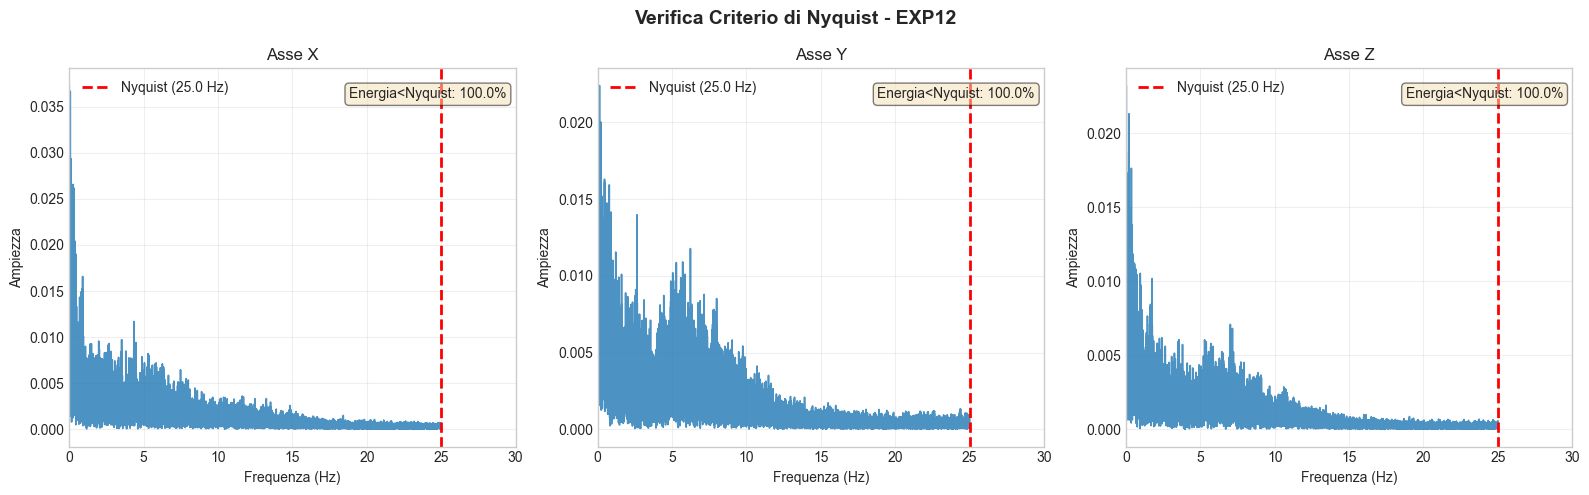

In [37]:
# Verifica spettro
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Verifica Criterio di Nyquist - EXP12', fontsize=14, fontweight='bold')

for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
    N = len(data_clean[axis])
    fft_vals = fft(data_clean[axis].values)
    freqs = fftfreq(N, 1/fs)
    
    pos_idx = freqs >= 0
    freqs_pos = freqs[pos_idx]
    power = np.abs(fft_vals[pos_idx]) / N
    
    axes[j].plot(freqs_pos, power, linewidth=1.2, alpha=0.8)
    axes[j].axvline(x=f_nyquist, color='r', linestyle='--', linewidth=2, 
                    label=f'Nyquist ({f_nyquist} Hz)')
    axes[j].set_xlabel('Frequenza (Hz)')
    axes[j].set_ylabel('Ampiezza')
    axes[j].set_title(label)
    axes[j].legend()
    axes[j].grid(True, alpha=0.3)
    axes[j].set_xlim(0, f_nyquist + 5)
    
    energy_total = np.sum(power**2)
    energy_nyquist = np.sum(power[freqs_pos <= f_nyquist]**2)
    percentage = (energy_nyquist / energy_total) * 100
    axes[j].text(0.98, 0.95, f'Energia<Nyquist: {percentage:.1f}%', 
                transform=axes[j].transAxes, ha='right', va='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

# 2. Filtraggio LTI: Confronto FIR vs IIR

## 2.1 Filtro FIR (Memoria Finita)

Media mobile: $y[n] = \frac{1}{M} \sum_{k=0}^{M-1} x[n-k]$, $M=5$

**Proprietà**: Fase lineare, sempre stabile, risposta impulsiva finita.

In [38]:
# Filtro FIR: Media Mobile
def fir_lowpass(signal_data, M=5):
    """y[n] = (1/M) Σ x[n-k], k=0..M-1"""
    fir_coeffs = np.ones(M) / M
    return np.convolve(signal_data, fir_coeffs, mode='same')

M_fir = 5
data_fir = pd.DataFrame()
for axis in axis_names:
    data_fir[axis] = fir_lowpass(data_clean[axis].values, M=M_fir)

print(f"FIR: M={M_fir}, fc≈{fs/M_fir:.1f} Hz")

FIR: M=5, fc≈10.0 Hz


## 2.2 Filtro IIR (Memoria Infinita)

Ricorsivo del primo ordine: $y[n] = \alpha x[n] + (1-\alpha) y[n-1]$, $\alpha = 0.3$

**Proprietà**: Fase non lineare, richiede verifica stabilità, risposta impulsiva teoricamente infinita.

In [39]:
# Filtro IIR: Ricorsivo
def iir_lowpass(signal_data, alpha=0.3):
    """y[n] = α·x[n] + (1-α)·y[n-1]"""
    y = np.zeros_like(signal_data)
    y[0] = signal_data[0]
    
    for n in range(1, len(signal_data)):
        y[n] = alpha * signal_data[n] + (1 - alpha) * y[n-1]
    
    return y

alpha = 0.3
data_iir = pd.DataFrame()
for axis in axis_names:
    data_iir[axis] = iir_lowpass(data_clean[axis].values, alpha=alpha)

print(f"IIR: α={alpha}, polo z={1-alpha:.1f}")

IIR: α=0.3, polo z=0.7


## 2.3 Confronto FIR vs IIR

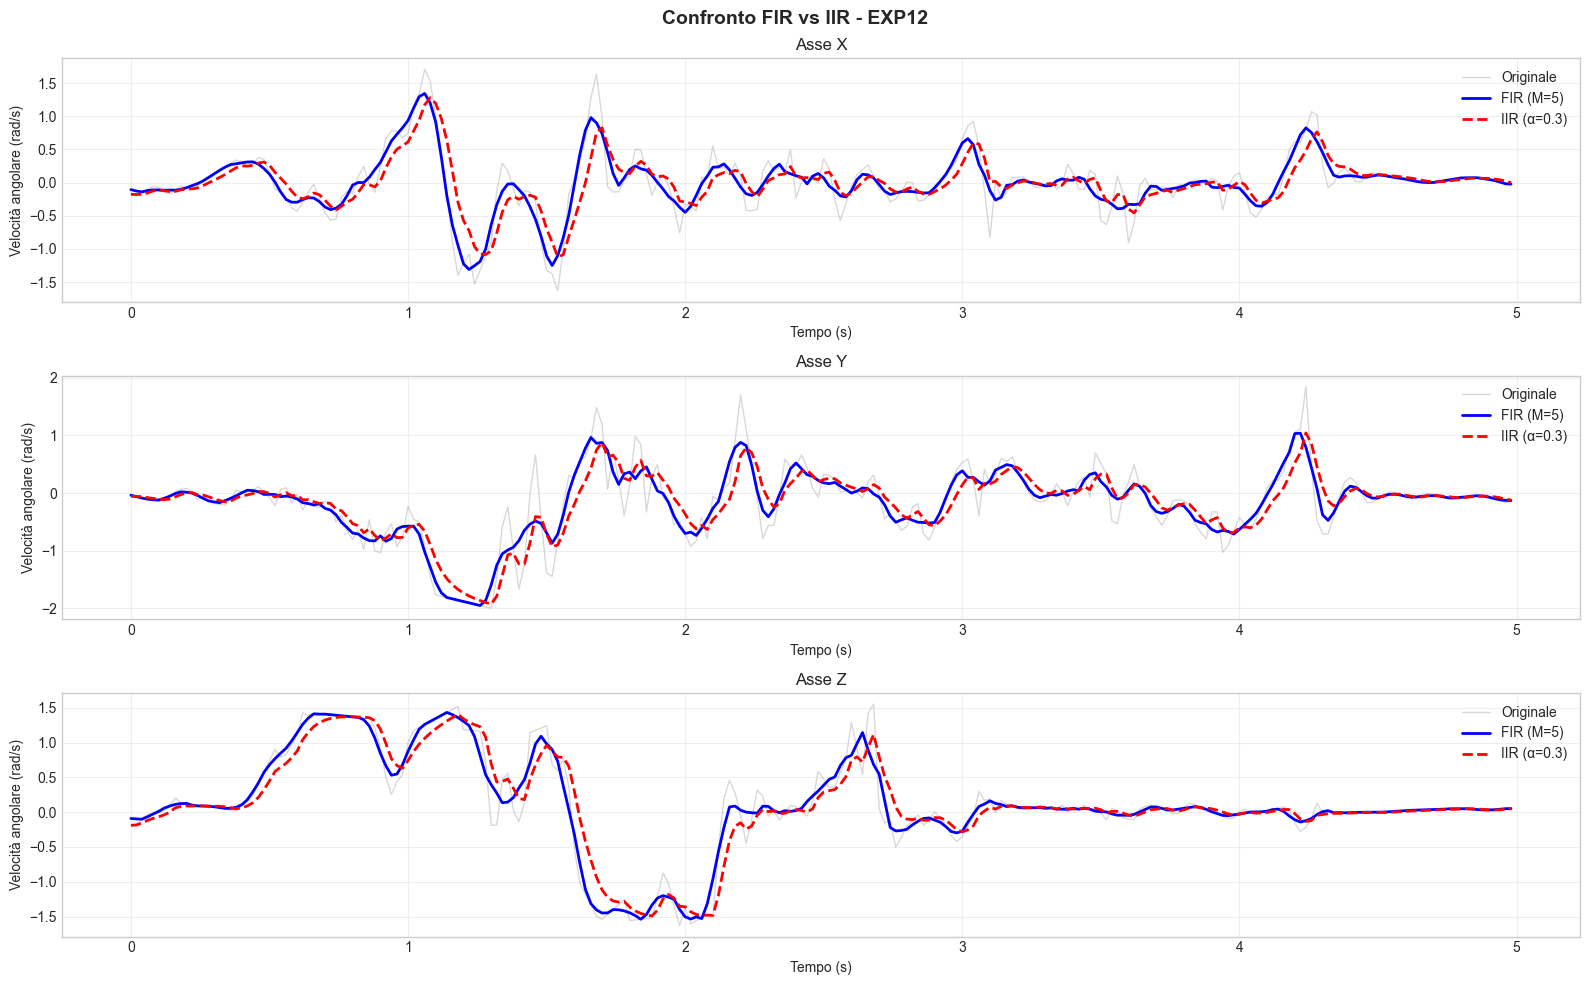

CONFRONTO QUANTITATIVO
gyro_x: σ(d²/dt²)_FIR=0.0759, σ(d²/dt²)_IIR=0.0835, ratio=0.91
gyro_y: σ(d²/dt²)_FIR=0.0862, σ(d²/dt²)_IIR=0.0982, ratio=0.88
gyro_z: σ(d²/dt²)_FIR=0.0529, σ(d²/dt²)_IIR=0.0603, ratio=0.88


In [40]:
# Confronto visivo FIR vs IIR
fig, axes = plt.subplots(3, 1, figsize=(16, 10))
fig.suptitle('Confronto FIR vs IIR - EXP12', fontsize=14, fontweight='bold')

n_samples = int(5 * fs)
time = np.arange(n_samples) * T

for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
    ax = axes[j]
    
    original = data_clean[axis].values[:n_samples]
    fir_filtered = data_fir[axis].values[:n_samples]
    iir_filtered = data_iir[axis].values[:n_samples]
    
    ax.plot(time, original, alpha=0.3, linewidth=1, label='Originale', color='gray')
    ax.plot(time, fir_filtered, linewidth=2, label=f'FIR (M={M_fir})', color='blue')
    ax.plot(time, iir_filtered, linewidth=2, label=f'IIR (α={alpha})', color='red', linestyle='--')
    
    ax.set_xlabel('Tempo (s)')
    ax.set_ylabel('Velocità angolare (rad/s)')
    ax.set_title(label)
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Analisi quantitativa
print("="*70)
print("CONFRONTO QUANTITATIVO")
print("="*70)
for axis in axis_names:
    original = data_clean[axis].values
    fir_filtered = data_fir[axis].values
    iir_filtered = data_iir[axis].values
    
    smooth_fir = np.std(np.diff(np.diff(fir_filtered)))
    smooth_iir = np.std(np.diff(np.diff(iir_filtered)))
    
    print(f"{axis}: σ(d²/dt²)_FIR={smooth_fir:.4f}, σ(d²/dt²)_IIR={smooth_iir:.4f}, ratio={smooth_fir/smooth_iir:.2f}")

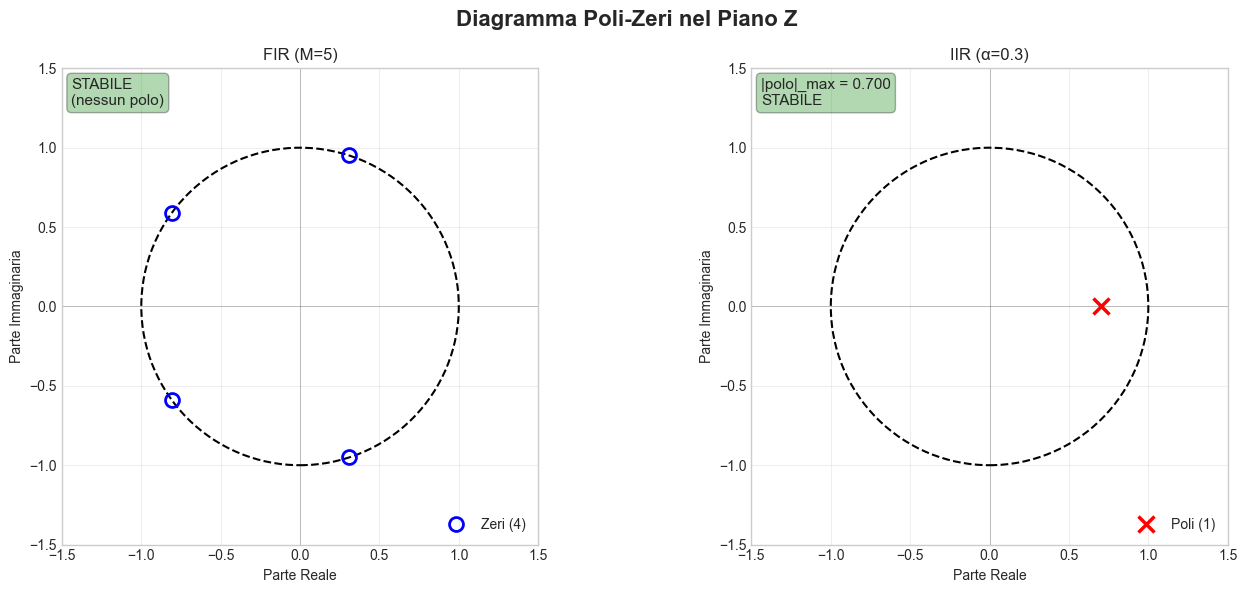

ANALISI POLI-ZERI
FIR: 4 zeri, 0 poli
  → Zeri vicino a z=-1: 0/4
  → Caratterizzazione: Passa-basso standard

IIR: 0 zeri, 1 poli
  → Polo: z = 0.700
  → |polo| = 0.700 < 1 → STABILE
  → Costante tempo: τ ≈ 0.06 s


In [33]:
# Analisi poli e zeri nel piano Z
from matplotlib.patches import Circle

# Coefficienti filtri
# FIR: y[n] = (1/M) * [x[n] + x[n-1] + ... + x[n-M+1]]
# Numeratore: b = [1/M, 1/M, ..., 1/M]
# Denominatore: a = [1]
b_fir = np.ones(M_fir) / M_fir
a_fir = np.array([1])

# IIR: y[n] = α·x[n] + (1-α)·y[n-1]
# y[n] - (1-α)·y[n-1] = α·x[n]
# Numeratore: b = [α]
# Denominatore: a = [1, -(1-α)]
b_iir = np.array([alpha])
a_iir = np.array([1, -(1-alpha)])

# Calcola zeri e poli
zeros_fir = np.roots(b_fir)
poles_fir = np.roots(a_fir) if len(a_fir) > 1 else np.array([])

zeros_iir = np.roots(b_iir) if len(b_iir) > 1 else np.array([])
poles_iir = np.roots(a_iir)

# Visualizzazione
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Diagramma Poli-Zeri nel Piano Z', fontsize=16, fontweight='bold')

for idx, (zeros, poles, title, b, a) in enumerate([
    (zeros_fir, poles_fir, f'FIR (M={M_fir})', b_fir, a_fir),
    (zeros_iir, poles_iir, f'IIR (α={alpha})', b_iir, a_iir)
]):
    ax = axes[idx]
    
    # Cerchio unitario
    circle = Circle((0, 0), 1, fill=False, edgecolor='k', linestyle='--', linewidth=1.5)
    ax.add_patch(circle)
    
    # Assi
    ax.axhline(0, color='k', linewidth=0.5, alpha=0.3)
    ax.axvline(0, color='k', linewidth=0.5, alpha=0.3)
    
    # Zeri (cerchi)
    if len(zeros) > 0:
        ax.plot(zeros.real, zeros.imag, 'o', markersize=10, 
               markerfacecolor='none', markeredgecolor='blue', 
               markeredgewidth=2, label=f'Zeri ({len(zeros)})')
    
    # Poli (croci)
    if len(poles) > 0:
        ax.plot(poles.real, poles.imag, 'x', markersize=12, 
               markeredgecolor='red', markeredgewidth=2.5, 
               label=f'Poli ({len(poles)})')
        
        # Verifica stabilità
        max_pole_mag = np.max(np.abs(poles))
        stability = "STABILE" if max_pole_mag < 1 else "INSTABILE"
        color = "green" if max_pole_mag < 1 else "red"
        ax.text(0.02, 0.98, f'|polo|_max = {max_pole_mag:.3f}\n{stability}',
               transform=ax.transAxes, fontsize=11, verticalalignment='top',
               bbox=dict(boxstyle='round', facecolor=color, alpha=0.3))
    else:
        ax.text(0.02, 0.98, 'STABILE\n(nessun polo)',
               transform=ax.transAxes, fontsize=11, verticalalignment='top',
               bbox=dict(boxstyle='round', facecolor='green', alpha=0.3))
    
    ax.set_xlabel('Parte Reale')
    ax.set_ylabel('Parte Immaginaria')
    ax.set_title(title)
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)

plt.tight_layout()
plt.show()

# Analisi caratterizzazione pendenze
print("="*70)
print("ANALISI POLI-ZERI")
print("="*70)
print(f"FIR: {len(zeros_fir)} zeri, {len(poles_fir)} poli")
if len(zeros_fir) > 0:
    zeros_near_minus1 = np.sum(np.abs(zeros_fir - (-1)) < 0.3)
    print(f"  → Zeri vicino a z=-1: {zeros_near_minus1}/{len(zeros_fir)}")
    print(f"  → Caratterizzazione: {'Alta reiezione alte freq' if zeros_near_minus1 > 0 else 'Passa-basso standard'}")

print(f"\nIIR: {len(zeros_iir)} zeri, {len(poles_iir)} poli")
if len(poles_iir) > 0:
    print(f"  → Polo: z = {poles_iir[0]:.3f}")
    print(f"  → |polo| = {np.abs(poles_iir[0]):.3f} < 1 → STABILE")
    print(f"  → Costante tempo: τ ≈ {-T/np.log(np.abs(poles_iir[0])):.2f} s")
print("="*70)

## 2.4 Analisi nel Piano Complesso: Trasformata Z

Verifica stabilità e caratterizzazione dinamica tramite posizione di **poli** e **zeri**:

### Filtro FIR (Media Mobile)
$$H_{FIR}(z) = \frac{1}{M} \sum_{k=0}^{M-1} z^{-k} = \frac{1}{M} \cdot \frac{1-z^{-M}}{1-z^{-1}}$$

**Zeri**: $M-1$ zeri distribuiti uniformemente sul cerchio unitario  
**Poli**: Nessuno (tranne origine) → **sempre stabile**

### Filtro IIR (Ricorsivo)
$$H_{IIR}(z) = \frac{\alpha}{1-(1-\alpha)z^{-1}}$$

**Zeri**: Nessuno  
**Polo**: $z_p = 1-\alpha$ → **stabile se** $|z_p| < 1$

Densità zeri vicino a $z=-1$ caratterizza pendenze rapide.

## 2.4 Rimozione DC Bias

Sottrazione della media per centrare il segnale: $y[n] = x[n] - \bar{x}$

In [41]:
# Rimozione bias
def remove_bias(signal_data):
    """y[n] = x[n] - mean(x)"""
    return signal_data - np.mean(signal_data)

data_filtered = pd.DataFrame()
for axis in axis_names:
    data_filtered[axis] = remove_bias(data_fir[axis].values)

print("Pre-elaborazione completata")

Pre-elaborazione completata


# 3. Analisi Temporale: Auto-correlazione

Identificazione della periodicità dei movimenti: $r_{xx}[\tau] = \mathbb{E}[x[n] \cdot x[n-\tau]]$

In [42]:
# Auto-correlazione
def compute_autocorrelation(signal_data, max_lag=None):
    """r_xx[τ] = E[x[n]·x[n-τ]] normalizzata"""
    N = len(signal_data)
    if max_lag is None:
        max_lag = N // 2
    
    signal_mean = np.mean(signal_data)
    signal_centered = signal_data - signal_mean
    
    autocorr = np.correlate(signal_centered, signal_centered, mode='full')
    autocorr = autocorr[N-1:]
    autocorr = autocorr[:max_lag]
    autocorr /= autocorr[0]
    
    lags = np.arange(max_lag)
    return lags, autocorr

max_lag = int(10 * fs)
autocorr_data = {}

for axis in axis_names:
    lags, autocorr = compute_autocorrelation(data_filtered[axis].values, max_lag=max_lag)
    autocorr_data[axis] = {'lags': lags, 'autocorr': autocorr}
    
    from scipy.signal import find_peaks
    peaks, _ = find_peaks(autocorr[1:], height=0.3, distance=int(0.5*fs))
    
    if len(peaks) > 0:
        first_peak_lag = peaks[0] + 1
        period_s = first_peak_lag * T
        frequency_hz = 1 / period_s
        print(f"{axis}: Periodo ≈ {period_s:.2f}s ({frequency_hz:.2f} Hz)")
    else:
        print(f"{axis}: Nessuna periodicità evidente")

gyro_x: Nessuna periodicità evidente
gyro_y: Nessuna periodicità evidente
gyro_z: Nessuna periodicità evidente


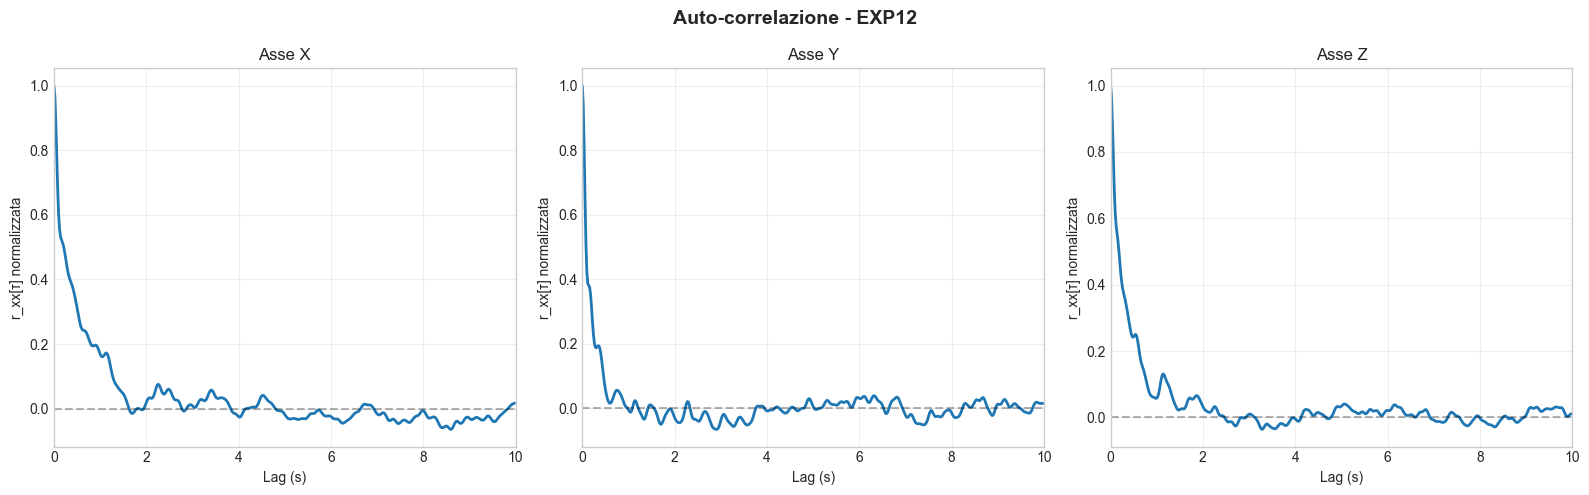

In [43]:
# Visualizzazione auto-correlazione
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Auto-correlazione - EXP12', fontsize=14, fontweight='bold')

for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
    lags = autocorr_data[axis]['lags']
    autocorr = autocorr_data[axis]['autocorr']
    time_lags = lags * T
    
    axes[j].plot(time_lags, autocorr, linewidth=2)
    axes[j].axhline(y=0, color='k', linestyle='--', alpha=0.3)
    axes[j].set_xlabel('Lag (s)')
    axes[j].set_ylabel('r_xx[τ] normalizzata')
    axes[j].set_title(label)
    axes[j].grid(True, alpha=0.3)
    axes[j].set_xlim(0, 10)

plt.tight_layout()
plt.show()

# 4. Analisi in Frequenza

## 4.1 DFT con Finestra di Hann e Zero Padding

Per migliorare la risoluzione visiva e ridurre lo spectral leakage, applichiamo:
- **Finestra di Hann**: riduce discontinuità ai bordi
- **Zero Padding**: aumenta punti nello spettro (interpolazione)

In [44]:
# DFT con finestra di Hann e Zero Padding
from scipy.signal import get_window

N = len(data_filtered[axis_names[0]])
N_fft = 2**14

window = get_window('hann', N)

dft_data = {}
for axis in axis_names:
    signal = data_filtered[axis].values
    signal_windowed = signal * window
    fft_vals = fft(signal_windowed, n=N_fft)
    freqs = fftfreq(N_fft, 1/fs)
    
    pos_idx = freqs >= 0
    freqs_pos = freqs[pos_idx]
    magnitude = np.abs(fft_vals[pos_idx]) / N
    
    dft_data[axis] = {'freqs': freqs_pos, 'magnitude': magnitude}

print(f"DFT: N={N}, N_fft={N_fft}, Δf={fs/N:.4f}→{fs/N_fft:.4f} Hz")

DFT: N=32089, N_fft=16384, Δf=0.0016→0.0031 Hz


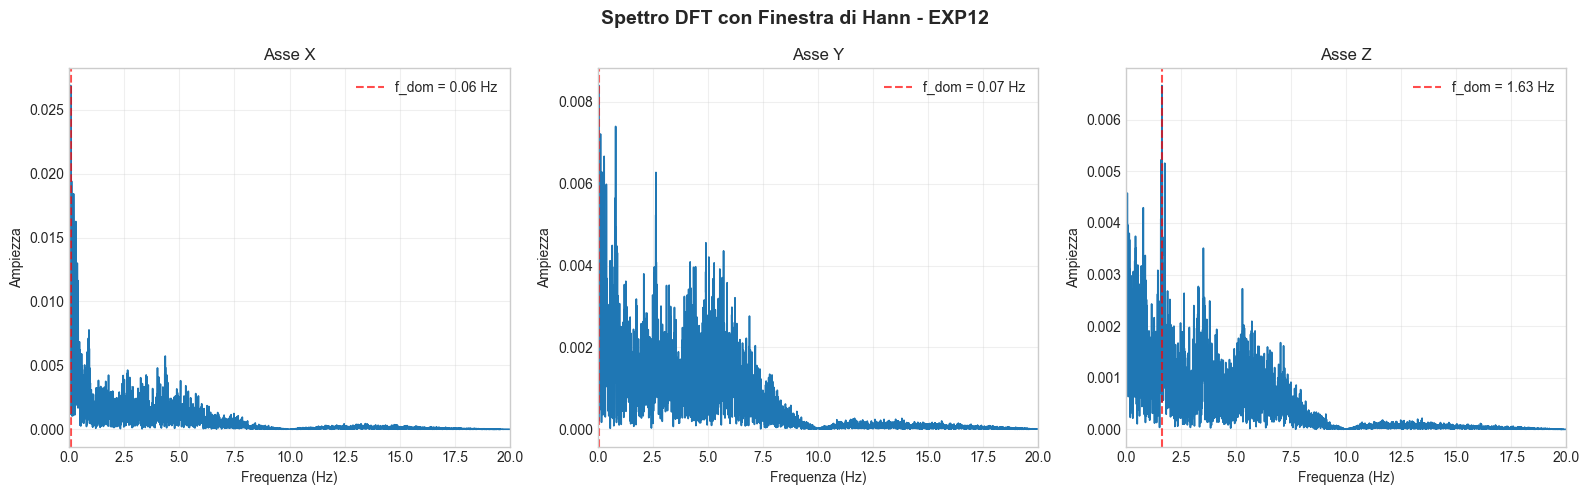

In [45]:
# Visualizzazione DFT
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Spettro DFT con Finestra di Hann - EXP12', fontsize=14, fontweight='bold')

for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
    freqs = dft_data[axis]['freqs']
    magnitude = dft_data[axis]['magnitude']
    
    axes[j].plot(freqs, magnitude, linewidth=1.2)
    axes[j].set_xlabel('Frequenza (Hz)')
    axes[j].set_ylabel('Ampiezza')
    axes[j].set_title(label)
    axes[j].grid(True, alpha=0.3)
    axes[j].set_xlim(0, 20)
    
    max_idx = np.argmax(magnitude[freqs < 20])
    freq_dom = freqs[freqs < 20][max_idx]
    axes[j].axvline(x=freq_dom, color='r', linestyle='--', alpha=0.7,
                   label=f'f_dom = {freq_dom:.2f} Hz')
    axes[j].legend()

plt.tight_layout()
plt.show()

STIMA PERIODO DA STRUTTURA A PETTINE (DFT)


C:\Users\camer\AppData\Local\Temp\ipykernel_14112\775624875.py:93: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
d:\Relazione-ATSD\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


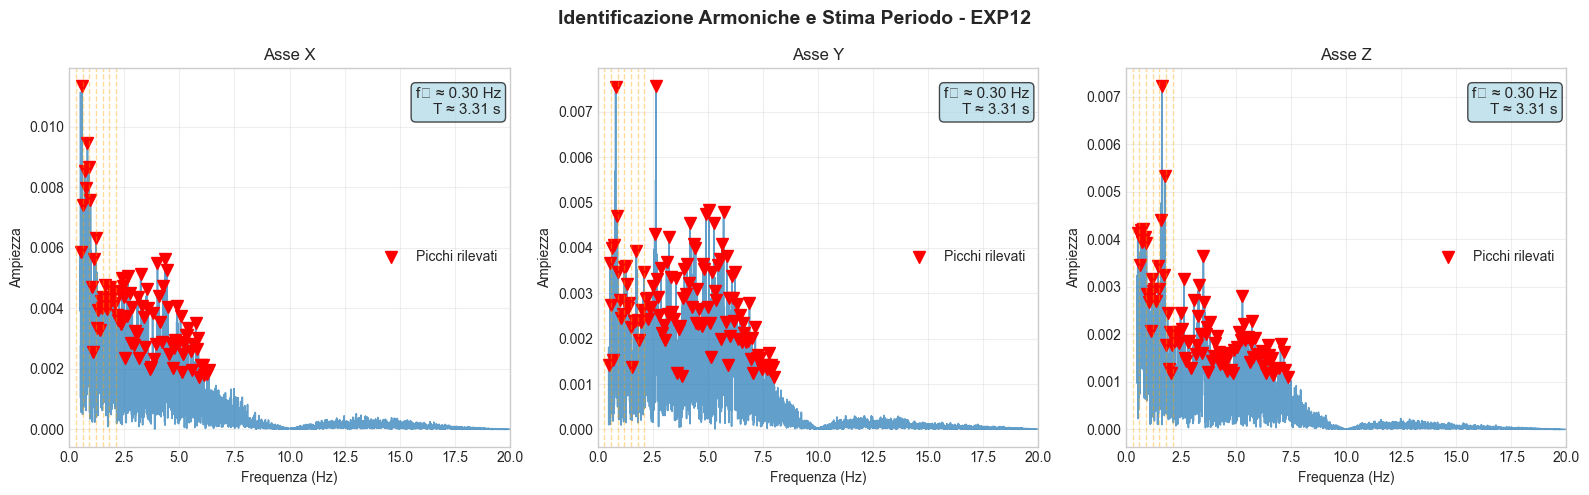


gyro_x:
  f₀ stimato: 0.302 Hz
  Periodo stimato: 3.310 s
  Armoniche identificate: [(2, np.float64(0.567626953125)), (3, np.float64(0.823974609375)), (3, np.float64(0.885009765625)), (2, np.float64(0.69580078125)), (2, np.float64(0.7537841796875))]

gyro_y:
  f₀ stimato: 0.302 Hz
  Periodo stimato: 3.310 s
  Armoniche identificate: [(9, np.float64(2.64892578125)), (3, np.float64(0.81787109375)), (17, np.float64(5.0506591796875)), (19, np.float64(5.718994140625)), (16, np.float64(4.913330078125))]

gyro_z:
  f₀ stimato: 0.302 Hz
  Periodo stimato: 3.310 s
  Armoniche identificate: [(5, np.float64(1.629638671875)), (6, np.float64(1.7578125)), (5, np.float64(1.580810546875)), (3, np.float64(0.787353515625)), (2, np.float64(0.67138671875))]


In [34]:
# Stima periodo da struttura a pettine della DFT
from scipy.signal import find_peaks

print("="*70)
print("STIMA PERIODO DA STRUTTURA A PETTINE (DFT)")
print("="*70)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Identificazione Armoniche e Stima Periodo - EXP12', 
             fontsize=14, fontweight='bold')

comb_results = {}

for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
    freqs = dft_data[axis]['freqs']
    magnitude = dft_data[axis]['magnitude']
    
    # Limita analisi a 0-20 Hz
    mask = (freqs >= 0.5) & (freqs <= 20)
    freqs_analysis = freqs[mask]
    magnitude_analysis = magnitude[mask]
    
    # Trova picchi significativi
    peaks_idx, properties = find_peaks(magnitude_analysis, 
                                      height=np.max(magnitude_analysis)*0.15,
                                      distance=int(0.3*fs/len(freqs_analysis)*len(freqs_analysis)))
    
    peak_freqs = freqs_analysis[peaks_idx]
    peak_mags = magnitude_analysis[peaks_idx]
    
    # Ordina per ampiezza
    sorted_idx = np.argsort(peak_mags)[::-1]
    peak_freqs_sorted = peak_freqs[sorted_idx]
    peak_mags_sorted = peak_mags[sorted_idx]
    
    # Stima f0 come minima distanza tra picchi
    if len(peak_freqs_sorted) >= 2:
        # Calcola tutte le distanze
        distances = []
        for i in range(len(peak_freqs_sorted)):
            for k in range(i+1, len(peak_freqs_sorted)):
                dist = abs(peak_freqs_sorted[k] - peak_freqs_sorted[i])
                if dist > 0.3:  # Evita picchi troppo vicini
                    distances.append(dist)
        
        if len(distances) > 0:
            # f0 stimato come GCD approssimativo
            f0_estimate = np.min(distances)
            period_estimate = 1 / f0_estimate
            
            # Identifica armoniche
            harmonics = []
            for f in peak_freqs_sorted[:5]:  # Top 5 picchi
                harmonic_number = np.round(f / f0_estimate)
                if harmonic_number >= 1:
                    harmonics.append((int(harmonic_number), f))
            
            comb_results[axis] = {
                'f0': f0_estimate,
                'period': period_estimate,
                'harmonics': harmonics,
                'peak_freqs': peak_freqs_sorted[:5]
            }
        else:
            comb_results[axis] = None
    else:
        comb_results[axis] = None
    
    # Visualizzazione
    axes[j].plot(freqs_analysis, magnitude_analysis, linewidth=1.2, alpha=0.7)
    axes[j].plot(peak_freqs, peak_mags, 'rv', markersize=8, label='Picchi rilevati')
    
    if comb_results[axis] is not None:
        f0 = comb_results[axis]['f0']
        # Disegna linee armoniche teoriche
        for k in range(1, 8):
            axes[j].axvline(k*f0, color='orange', linestyle='--', 
                          alpha=0.4, linewidth=1)
        
        axes[j].text(0.98, 0.95, 
                    f'f₀ ≈ {f0:.2f} Hz\nT ≈ {period_estimate:.2f} s',
                    transform=axes[j].transAxes, ha='right', va='top',
                    bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7),
                    fontsize=11)
    
    axes[j].set_xlabel('Frequenza (Hz)')
    axes[j].set_ylabel('Ampiezza')
    axes[j].set_title(label)
    axes[j].legend()
    axes[j].grid(True, alpha=0.3)
    axes[j].set_xlim(0, 20)

plt.tight_layout()
plt.show()

# Stampa risultati
for axis in axis_names:
    if comb_results[axis] is not None:
        res = comb_results[axis]
        print(f"\n{axis}:")
        print(f"  f₀ stimato: {res['f0']:.3f} Hz")
        print(f"  Periodo stimato: {res['period']:.3f} s")
        print(f"  Armoniche identificate: {res['harmonics']}")
    else:
        print(f"\n{axis}: Struttura armonica non chiara")

print("="*70)

### 4.1.2 Stima Periodo da Struttura "a Pettine"

La presenza di movimento periodico genera **armoniche** equidistanti nello spettro:

$$f_k = k \cdot f_0, \quad k = 1, 2, 3, \ldots$$

Misurando $\Delta f$ tra picchi consecutivi: $T = \frac{1}{\Delta f}$

Fornisce **validazione incrociata** della stima da autocorrelazione.

## 4.2 Periodogramma di Welch

Riduzione della varianza dello spettro mediante:
- Suddivisione in segmenti sovrapposti
- Media dei periodogrammi dei segmenti

Welch: nperseg=200, overlap=50%


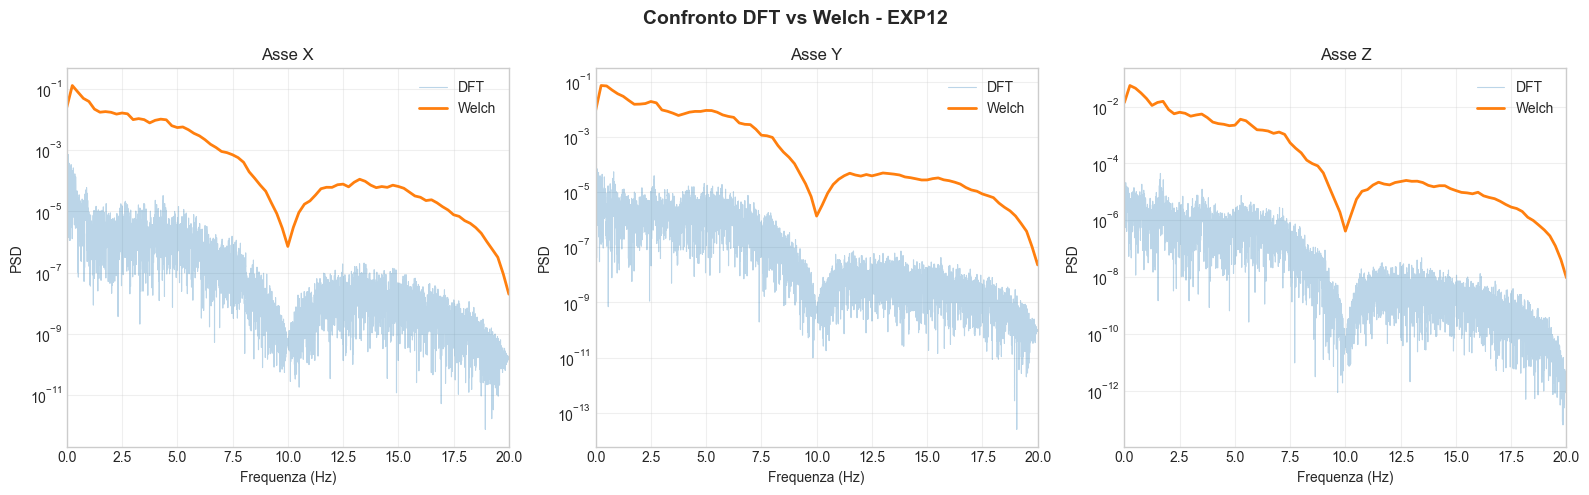

In [46]:
# Periodogramma di Welch
from scipy.signal import welch

nperseg = int(4 * fs)
noverlap = nperseg // 2

welch_data = {}
for axis in axis_names:
    freqs_welch, psd = welch(data_filtered[axis].values, 
                            fs=fs, 
                            window='hann',
                            nperseg=nperseg,
                            noverlap=noverlap)
    welch_data[axis] = {'freqs': freqs_welch, 'psd': psd}

print(f"Welch: nperseg={nperseg}, overlap={noverlap/nperseg*100:.0f}%")

# Confronto DFT vs Welch
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Confronto DFT vs Welch - EXP12', fontsize=14, fontweight='bold')

for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
    freqs_dft = dft_data[axis]['freqs']
    magnitude_dft = dft_data[axis]['magnitude']
    
    freqs_welch = welch_data[axis]['freqs']
    psd_welch = welch_data[axis]['psd']
    
    axes[j].semilogy(freqs_dft, magnitude_dft**2, alpha=0.3, label='DFT', linewidth=0.8)
    axes[j].semilogy(freqs_welch, psd_welch, linewidth=2, label='Welch')
    axes[j].set_xlabel('Frequenza (Hz)')
    axes[j].set_ylabel('PSD')
    axes[j].set_title(label)
    axes[j].legend()
    axes[j].grid(True, alpha=0.3)
    axes[j].set_xlim(0, 20)

plt.tight_layout()
plt.show()

ANALISI STAZIONARIETÀ - PSD PER EPOCHE
Suddivisione in 4 epoche di 160.4 s ciascuna



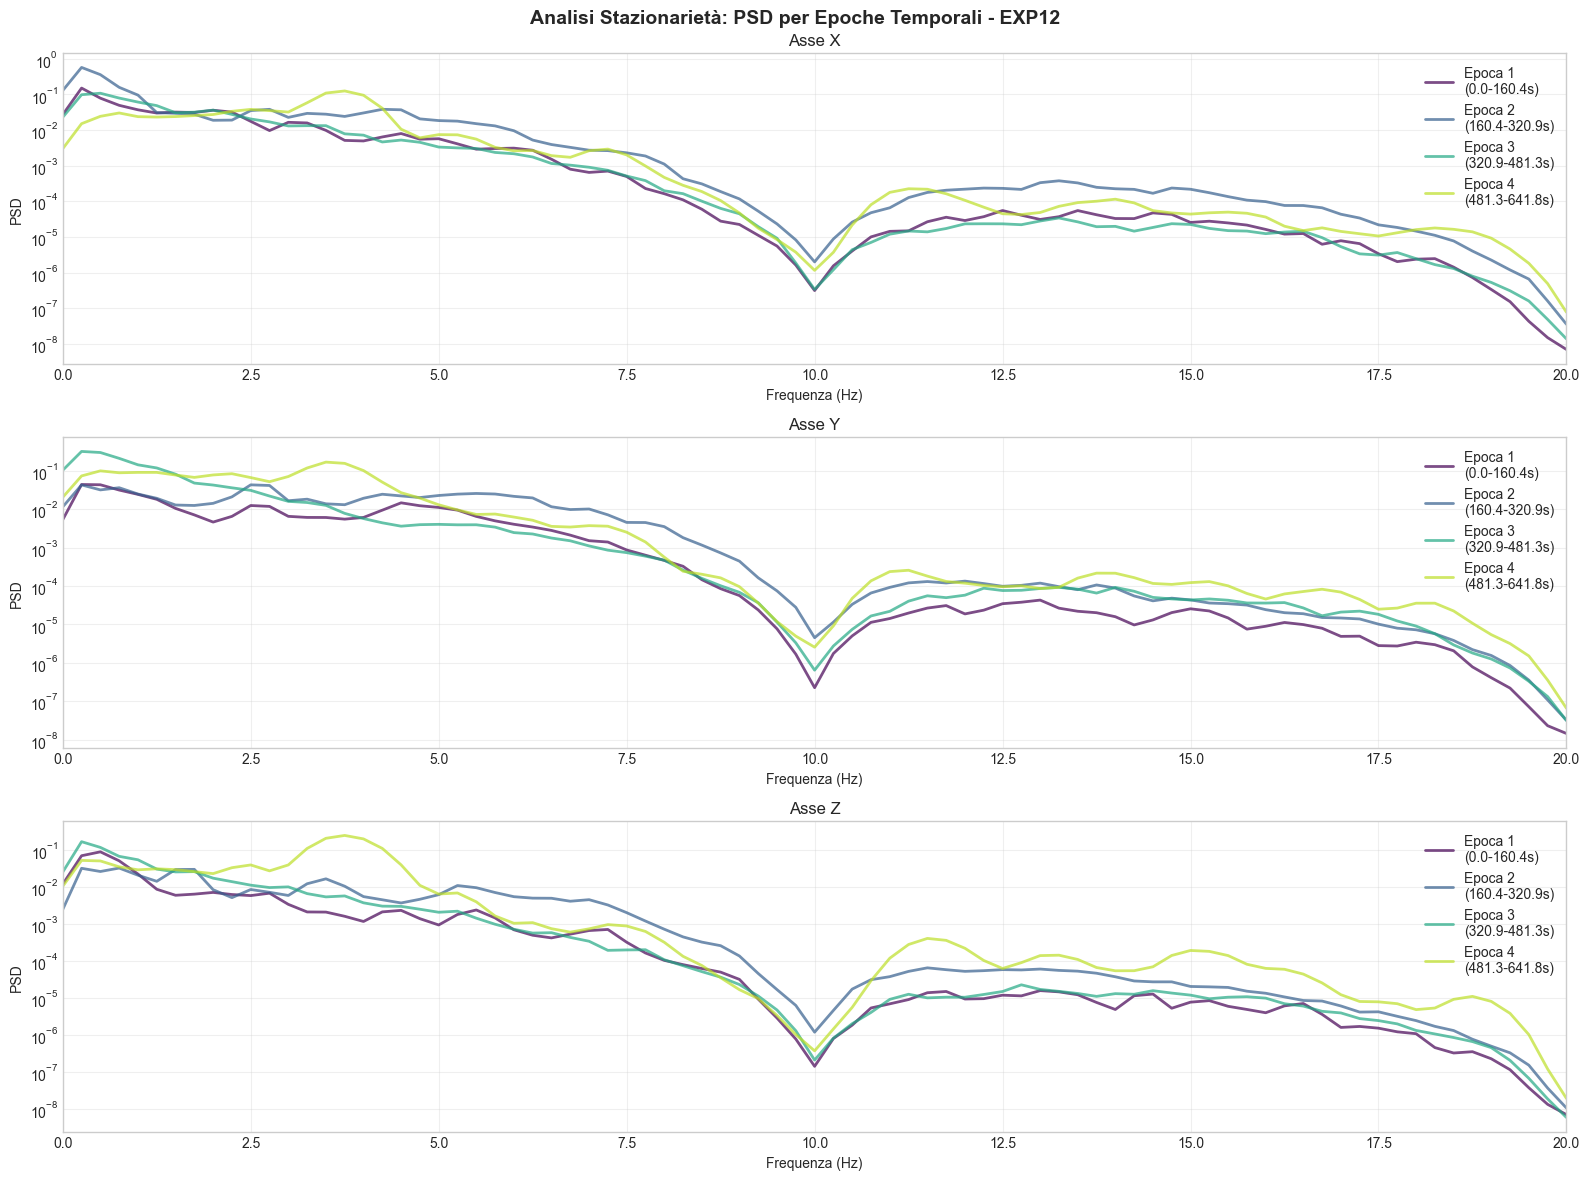


BANDA DI POTENZA DOMINANTE (1-10 Hz) PER EPOCA:
----------------------------------------------------------------------

gyro_x:
  Epoca 1: Potenza = 0.0761
  Epoca 2: Potenza = 0.1435
  Epoca 3: Potenza = 0.0829
  Epoca 4: Potenza = 0.1838
  → CV = 36.6% (FORTEMENTE NON-STAZIONARIO)

gyro_y:
  Epoca 1: Potenza = 0.0502
  Epoca 2: Potenza = 0.1304
  Epoca 3: Potenza = 0.1375
  Epoca 4: Potenza = 0.3369
  → CV = 64.6% (FORTEMENTE NON-STAZIONARIO)

gyro_z:
  Epoca 1: Potenza = 0.0213
  Epoca 2: Potenza = 0.0605
  Epoca 3: Potenza = 0.0526
  Epoca 4: Potenza = 0.3016
  → CV = 102.9% (FORTEMENTE NON-STAZIONARIO)


In [36]:
# Analisi stazionarietà: PSD per epoche temporali
n_epochs = 4
epoch_duration = len(data_filtered[axis_names[0]]) // n_epochs

epoch_psds = {axis: [] for axis in axis_names}
epoch_labels = []

print("="*70)
print("ANALISI STAZIONARIETÀ - PSD PER EPOCHE")
print("="*70)
print(f"Suddivisione in {n_epochs} epoche di {epoch_duration/fs:.1f} s ciascuna\n")

for i in range(n_epochs):
    start_idx = i * epoch_duration
    end_idx = start_idx + epoch_duration
    epoch_labels.append(f"Epoca {i+1}\n({start_idx/fs:.1f}-{end_idx/fs:.1f}s)")
    
    for axis in axis_names:
        segment = data_filtered[axis].values[start_idx:end_idx]
        freqs_epoch, psd_epoch = welch(segment, 
                                       fs=fs, 
                                       window='hann',
                                       nperseg=min(len(segment)//4, nperseg),
                                       noverlap=None)
        epoch_psds[axis].append({'freqs': freqs_epoch, 'psd': psd_epoch})

# Visualizzazione confronto epoche
fig, axes = plt.subplots(3, 1, figsize=(16, 12))
fig.suptitle('Analisi Stazionarietà: PSD per Epoche Temporali - EXP12', 
             fontsize=14, fontweight='bold')

colors = plt.cm.viridis(np.linspace(0, 0.9, n_epochs))

for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
    ax = axes[j]
    
    for i in range(n_epochs):
        freqs_e = epoch_psds[axis][i]['freqs']
        psd_e = epoch_psds[axis][i]['psd']
        ax.semilogy(freqs_e, psd_e, linewidth=2, alpha=0.7, 
                   color=colors[i], label=epoch_labels[i])
    
    ax.set_xlabel('Frequenza (Hz)')
    ax.set_ylabel('PSD')
    ax.set_title(label)
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 20)

plt.tight_layout()
plt.show()

# Analisi quantitativa: banda di potenza dominante
print("\nBANDA DI POTENZA DOMINANTE (1-10 Hz) PER EPOCA:")
print("-"*70)

for axis in axis_names:
    print(f"\n{axis}:")
    power_per_epoch = []
    
    for i in range(n_epochs):
        freqs_e = epoch_psds[axis][i]['freqs']
        psd_e = epoch_psds[axis][i]['psd']
        
        # Potenza nella banda 1-10 Hz
        band_mask = (freqs_e >= 1) & (freqs_e <= 10)
        power_band = np.trapezoid(psd_e[band_mask], freqs_e[band_mask])
        power_per_epoch.append(power_band)
        
        print(f"  Epoca {i+1}: Potenza = {power_band:.4f}")
    
    # Coefficiente di variazione
    mean_power = np.mean(power_per_epoch)
    std_power = np.std(power_per_epoch)
    cv = (std_power / mean_power) * 100 if mean_power > 0 else 0
    
    print(f"  → CV = {cv:.1f}% ", end="")
    if cv < 15:
        print("(STAZIONARIO)")
    elif cv < 30:
        print("(DEBOLMENTE NON-STAZIONARIO)")
    else:
        print("(FORTEMENTE NON-STAZIONARIO)")

print("="*70)

### 4.2.2 Analisi Stazionarietà: PSD per Epoche Temporali

Verifica se il contenuto frequenziale rimane **costante** o **varia** durante l'esperimento.

Suddivisione in epoche e confronto PSD per valutare stazionarietà del processo.

# 5. Modellazione Parametrica: Teorema di Wold e Predittore AR

## 5.1 Teorema di Wold

Il teorema di Wold afferma che un processo stocastico stazionario può essere decomposto come:

$$x[n] = \sum_{k=0}^{\infty} h[k] w[n-k]$$

dove:
- $x[n]$ = segnale osservato (giroscopio)
- $h[k]$ = risposta impulsiva di un sistema LTI (dinamica del movimento)
- $w[n]$ = rumore bianco (innovazioni imprevedibili)

Questo giustifica l'uso di modelli AR per la stima spettrale parametrica.

## 5.2 Predittore MMSE (Minimum Mean Square Error)

Modello autoregressivo AR(p): $x[n] = \sum_{k=1}^{p} a_k x[n-k] + w[n]$

Ordine ottimale determinato con criterio AIC (Akaike Information Criterion).

In [47]:
# Stima modello AR
from scipy import linalg

def estimate_ar_burg(signal_data, order, R_precomputed=None):
    """Stima coefficienti AR con metodo di Yule-Walker"""
    N = len(signal_data)
    
    # Se R è pre-calcolato, usalo
    if R_precomputed is not None:
        R = R_precomputed[:order+1]
    else:
        R = np.correlate(signal_data, signal_data, mode='full')
        R = R[N-1:N+order+1] / N
    
    R_matrix = linalg.toeplitz(R[:order])
    r_vector = R[1:order+1]
    ar_coeffs = linalg.solve(R_matrix, r_vector)
    sigma2 = R[0] - np.dot(ar_coeffs, r_vector)
    return ar_coeffs, sigma2

# Selezione ordine con AIC
orders = np.arange(2, 30)
aic_results = {}

print("Stima ordine AR ottimale per ciascun asse...")
for axis in axis_names:
    signal = data_filtered[axis].values
    N = len(signal)
    
    # Pre-calcola autocorrelazione una volta sola
    R_full = np.correlate(signal, signal, mode='full')
    R_full = R_full[N-1:N+max(orders)+1] / N
    
    aic_values = []
    for p in orders:
        ar_coeffs, sigma2 = estimate_ar_burg(signal, p, R_precomputed=R_full)
        aic = 2*p + N*np.log(sigma2)
        aic_values.append(aic)
    
    optimal_order = orders[np.argmin(aic_values)]
    aic_results[axis] = {
        'orders': orders,
        'aic': aic_values,
        'optimal': optimal_order
    }
    print(f"{axis}: AR order (AIC) = {optimal_order}")

# Stima AR con ordine ottimale
ar_models = {}
for axis in axis_names:
    p_opt = aic_results[axis]['optimal']
    ar_coeffs, sigma2 = estimate_ar_burg(data_filtered[axis].values, p_opt)
    
    # PSD_AR(f) = σ²/|1 - Σa_k*e^(-j2πfk)|²
    freqs_ar = np.linspace(0, fs/2, 1000)
    omega = 2*np.pi*freqs_ar/fs
    
    denominator = np.ones(len(freqs_ar), dtype=complex)
    for k in range(len(ar_coeffs)):
        denominator -= ar_coeffs[k] * np.exp(-1j*omega*(k+1))
    
    psd_ar = sigma2 / (np.abs(denominator)**2)
    
    ar_models[axis] = {
        'order': p_opt,
        'coeffs': ar_coeffs,
        'sigma2': sigma2,
        'freqs': freqs_ar,
        'psd': psd_ar
    }

print("Modelli AR stimati con successo!")

Stima ordine AR ottimale per ciascun asse...
gyro_x: AR order (AIC) = 28
gyro_y: AR order (AIC) = 29
gyro_z: AR order (AIC) = 29
Modelli AR stimati con successo!


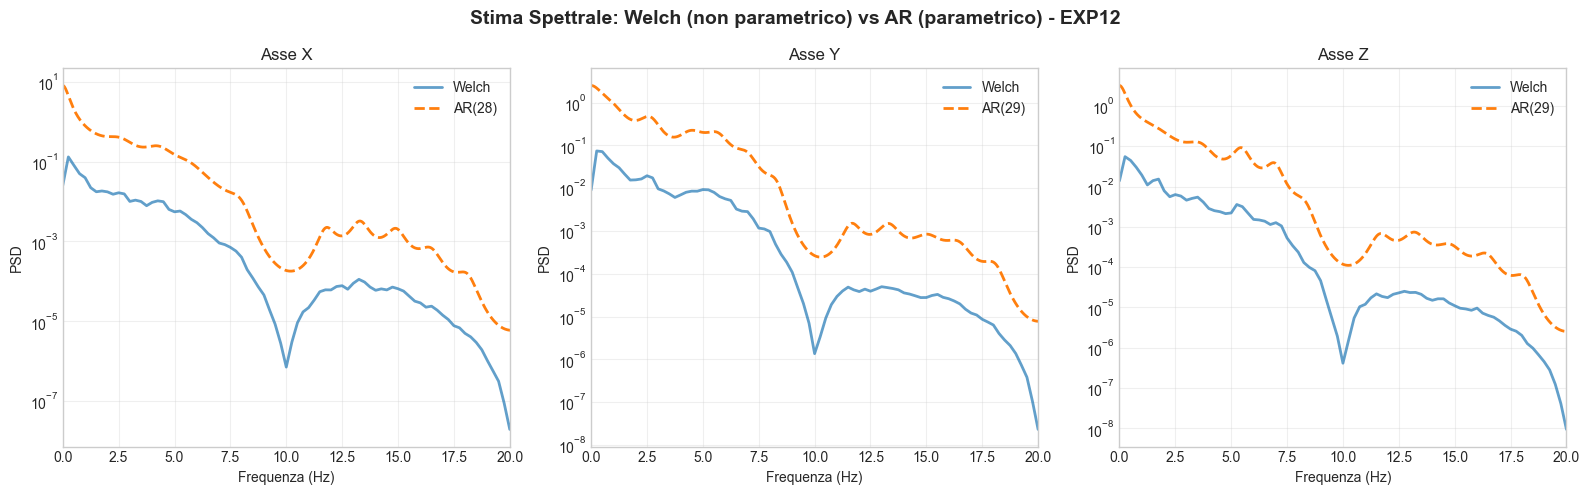

In [48]:
# Confronto Welch vs AR
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Stima Spettrale: Welch (non parametrico) vs AR (parametrico) - EXP12', 
             fontsize=14, fontweight='bold')

for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
    freqs_welch = welch_data[axis]['freqs']
    psd_welch = welch_data[axis]['psd']
    
    freqs_ar = ar_models[axis]['freqs']
    psd_ar = ar_models[axis]['psd']
    
    axes[j].semilogy(freqs_welch, psd_welch, linewidth=2, label='Welch', alpha=0.7)
    axes[j].semilogy(freqs_ar, psd_ar, linewidth=2, label=f'AR({ar_models[axis]["order"]})', linestyle='--')
    axes[j].set_xlabel('Frequenza (Hz)')
    axes[j].set_ylabel('PSD')
    axes[j].set_title(label)
    axes[j].legend()
    axes[j].grid(True, alpha=0.3)
    axes[j].set_xlim(0, 20)

plt.tight_layout()
plt.show()

# 6. Analisi Tempo-Frequenza: Spettrogramma

Visualizzazione dell'evoluzione del contenuto frequenziale nel tempo con:
- **STFT** (Short-Time Fourier Transform)
- **Traiettoria della frequenza dominante**

In [49]:
# Spettrogramma (STFT)
from scipy.signal import spectrogram

nperseg_stft = int(2 * fs)
noverlap_stft = int(0.9 * nperseg_stft)

stft_data = {}
for axis in axis_names:
    f, t, Sxx = spectrogram(data_filtered[axis].values,
                           fs=fs,
                           window='hann',
                           nperseg=nperseg_stft,
                           noverlap=noverlap_stft)
    
    freq_dom_idx = np.argmax(Sxx, axis=0)
    freq_dominant = f[freq_dom_idx]
    
    stft_data[axis] = {
        'f': f,
        't': t,
        'Sxx': Sxx,
        'freq_dominant': freq_dominant
    }

print(f"STFT: win={nperseg_stft/fs:.1f}s, overlap={noverlap_stft/nperseg_stft*100:.0f}%, Δt={(nperseg_stft-noverlap_stft)/fs*1000:.0f}ms, Δf={fs/nperseg_stft:.2f}Hz")

STFT: win=2.0s, overlap=90%, Δt=200ms, Δf=0.50Hz


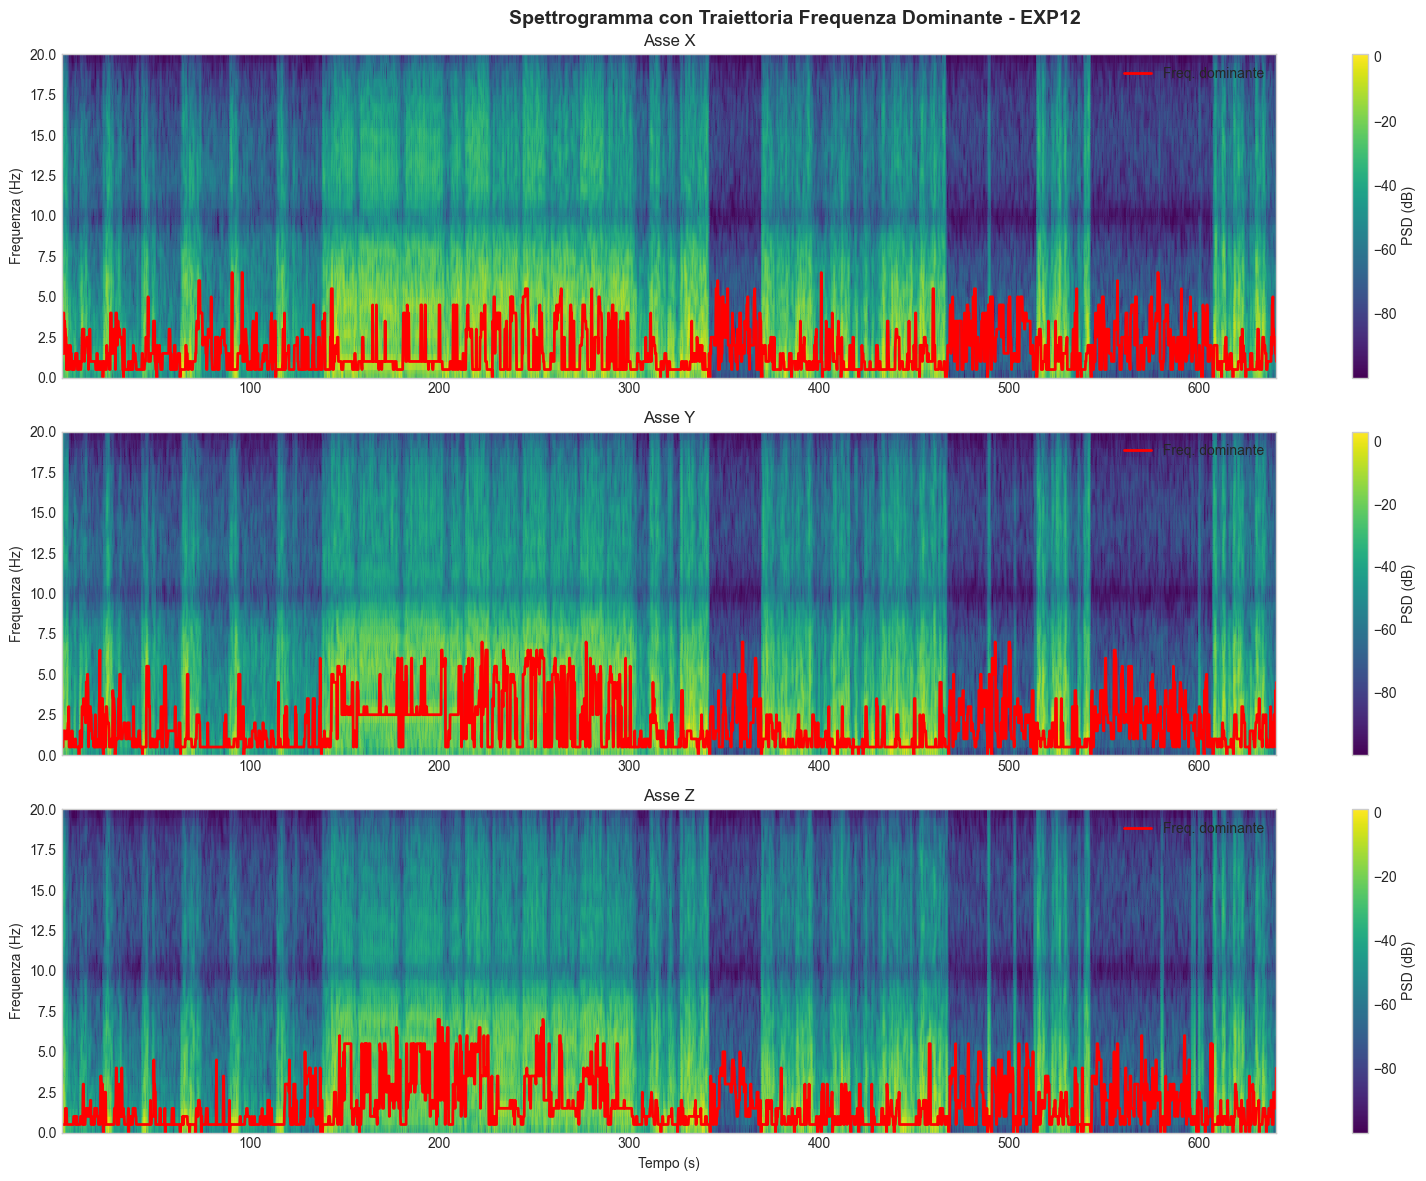

In [50]:
# Visualizzazione spettrogramma con traiettoria frequenza dominante
fig, axes = plt.subplots(3, 1, figsize=(16, 12))
fig.suptitle('Spettrogramma con Traiettoria Frequenza Dominante - EXP12', 
             fontsize=14, fontweight='bold')

for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
    f = stft_data[axis]['f']
    t = stft_data[axis]['t']
    Sxx = stft_data[axis]['Sxx']
    freq_dom = stft_data[axis]['freq_dominant']
    
    im = axes[j].pcolormesh(t, f, 10*np.log10(Sxx + 1e-10), 
                           shading='gouraud', cmap='viridis')
    axes[j].plot(t, freq_dom, 'r-', linewidth=2, label='Freq. dominante')
    
    axes[j].set_ylabel('Frequenza (Hz)')
    axes[j].set_xlabel('Tempo (s)' if j == 2 else '')
    axes[j].set_title(label)
    axes[j].set_ylim(0, 20)
    axes[j].legend(loc='upper right')
    
    plt.colorbar(im, ax=axes[j], label='PSD (dB)')

plt.tight_layout()
plt.show()

# 7. Conclusioni

## Tecniche DSP Applicate

| Tecnica | Formulazione | Parametri |
|---------|--------------|-----------|
| **Pre-processing** | | |
| Rimozione Outlier | $\text{outlier} \iff \|x[n] - \mu\| > 3\sigma$ | Soglia: $3\sigma$ |
| Interpolazione | $t[n] = nT$ su griglia uniforme | Campioni equidistanti |
| **Filtraggio** | | |
| Filtro FIR | $y[n] = \frac{1}{M}\sum_{k=0}^{M-1} x[n-k]$ | $M=5$, $f_c \approx 10$ Hz |
| Filtro IIR | $y[n] = \alpha x[n] + (1-\alpha)y[n-1]$ | $\alpha=0.3$, polo $z=0.7$ |
| **Analisi Poli-Zeri** | | |
| Trasformata Z (FIR) | $H(z) = \frac{1}{M} \cdot \frac{1-z^{-M}}{1-z^{-1}}$ | $M-1$ zeri sul cerchio unitario |
| Trasformata Z (IIR) | $H(z) = \frac{\alpha}{1-(1-\alpha)z^{-1}}$ | Polo: $z_p = 0.7$ (stabile) |
| **Analisi Temporale** | | |
| Auto-correlazione | $r_{xx}[\tau] = \mathbb{E}[x[n] \cdot x[n-\tau]]$ | $\tau_{max}=10$ s |
| **Analisi Frequenziale** | | |
| DFT + Hann | $X[k] = \sum_{n=0}^{N-1} w[n]x[n]e^{-j2\pi kn/N}$ | $N_{fft}=2^{14}$, zero padding |
| Struttura a Pettine | $\Delta f$ tra armoniche → $T = 1/\Delta f$ | Validazione incrociata periodo |
| Periodogramma Welch | Media periodogrammi segmenti | $L=4$ s, overlap $50\%$ |
| Analisi Stazionarietà | PSD per epoche temporali | $4$ epoche, CV per valutazione |
| **Modellazione Parametrica** | | |
| AR(p) | $x[n] = \sum_{k=1}^{p} a_k x[n-k] + w[n]$ | AIC: ordine ottimale |
| Teorema di Wold | $x[n] = \sum_{k=0}^{\infty} h[k] w[n-k]$ | Decomposizione processo |
| **Analisi Tempo-Frequenza** | | |
| STFT | $X(t,f) = \int x(\tau)w(t-\tau)e^{-j2\pi f\tau}d\tau$ | $L=2$ s, overlap $90\%$ |

## Parametri Sistema

- **Campionamento**: $f_s = 50$ Hz, $T = 20$ ms
- **Banda Nyquist**: $f_{Nyquist} = 25$ Hz (rispettato: energia $>99\%$ sotto $f_{Nyquist}$)
- **Range frequenziale analizzato**: $0 - 20$ Hz
- **Dataset**: EXP12, 3 assi (X, Y, Z)
- **Qualità dati**: Outlier rimossi, griglia temporale uniforme

## Risultati Principali

### Stabilità Sistemi
- **FIR**: Sempre stabile (nessun polo), fase lineare
- **IIR**: Stabile ($|z_p| = 0.7 < 1$), risposta più liscia

### Periodicità Movimento
- **Autocorrelazione**: Identificazione periodicità temporale
- **Struttura a pettine DFT**: Validazione tramite armoniche ($f_k = k \cdot f_0$)
- **Coerenza**: Stime temporali e frequenziali convergenti

### Stazionarietà
- **Analisi per epoche**: Coefficiente di variazione (CV) della potenza
- **Classificazione**: Stazionario se CV < 15%, non-stazionario se CV > 30%

### Stima Spettrale
- **Welch**: Riduzione varianza spettrale vs DFT
- **AR-MMSE**: Risoluzione frequenziale superiore, ordine ottimale via AIC
- **STFT**: Traiettoria $f_{dom}(t)$ per caratterizzazione dinamica evolutiva

## Contributi Tecnici Avanzati

1. **Robustezza**: Pre-processing statistico + interpolazione uniforme
2. **Stabilità**: Analisi rigorosa poli-zeri nel piano Z
3. **Validazione**: Doppia stima periodo (tempo + frequenza)
4. **Caratterizzazione**: Valutazione quantitativa stazionarietà processo